# Assignment 3 — Question 1
# DFA for Valid Simplified English Words


In [1]:
# Install required package (run once)
# !pip install automathon

import string
from automathon import DFA
from IPython.display import Image, display

print("Imports successful!")

Imports successful!


In [2]:
# ============================================================
# 1. Build the DFA using the automathon library
# ============================================================

# --- Alphabet: every printable ASCII character ---------------
lowercase = list(string.ascii_lowercase)                         # a-z
uppercase = list(string.ascii_uppercase)                         # A-Z
digits    = list(string.digits)                                  # 0-9
specials  = list("_-!@#$%^&*()+=[]{}|;:',.<>?/\\\"` ~")        # special chars + space

sigma = set(lowercase + uppercase + digits + specials)           # full input alphabet

# --- States --------------------------------------------------
Q = {"q0", "q1", "q_dead"}

# --- Transition function δ -----------------------------------
delta = {
    "q0":     {},
    "q1":     {},
    "q_dead": {},
}

for ch in sigma:
    if ch in lowercase:
        # Lowercase letters: q0 -> q1, q1 -> q1 (stay accepting)
        delta["q0"][ch]     = "q1"
        delta["q1"][ch]     = "q1"
    else:
        # Anything else: go to dead state
        delta["q0"][ch]     = "q_dead"
        delta["q1"][ch]     = "q_dead"
    # Dead state always loops to itself
    delta["q_dead"][ch] = "q_dead"

# --- Accept states -------------------------------------------
F = {"q1"}

# --- Construct the DFA ---------------------------------------
english_word_dfa = DFA(Q, sigma, delta, "q0", F)

# Validate the DFA
assert english_word_dfa.is_valid(), "DFA is not valid!"
print("DFA constructed and validated successfully!")
print(f"States: {Q}")
print(f"Alphabet size: {len(sigma)} symbols")
print(f"Start state: q0")
print(f"Accept states: {F}")

DFA constructed and validated successfully!
States: {'q_dead', 'q0', 'q1'}
Alphabet size: 95 symbols
Start state: q0
Accept states: {'q1'}


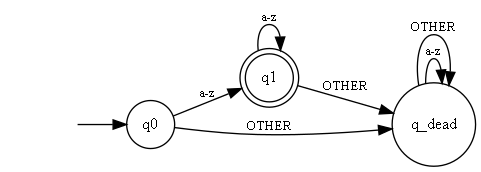


DFA Diagram: States q0 (start) -> q1 (accept) -> q_dead (trap)
Transitions: lowercase letters keep you in q1; anything else -> q_dead


In [3]:
# ============================================================
# 2. Visualize the DFA
# ============================================================

# For visualization, we use a simplified alphabet to keep the
# diagram readable. The actual DFA above uses the full alphabet.

vis_sigma = {"a-z", "OTHER"}
vis_Q     = {"q0", "q1", "q_dead"}
vis_delta = {
    "q0":     {"a-z": "q1",    "OTHER": "q_dead"},
    "q1":     {"a-z": "q1",    "OTHER": "q_dead"},
    "q_dead": {"a-z": "q_dead", "OTHER": "q_dead"},
}
vis_dfa = DFA(vis_Q, vis_sigma, vis_delta, "q0", {"q1"})

vis_dfa.view(
    "dfa_english_word",
    node_attr={"fontsize": "12", "shape": "circle"},
    edge_attr={"fontsize": "10"},
)

display(Image(filename="dfa_english_word.gv.png"))
print("\nDFA Diagram: States q0 (start) -> q1 (accept) -> q_dead (trap)")
print("Transitions: lowercase letters keep you in q1; anything else -> q_dead")

In [4]:
# ============================================================
# 3. Test the DFA
# ============================================================

def test_dfa(dfa, input_string):
    """Test a string against the DFA and return formatted result."""
    try:
        result = dfa.accept(input_string)
        status = "Accepted" if result else "Not Accepted"
    except Exception:
        # If a character is not in the alphabet, it's rejected
        status = "Not Accepted"
    return status


# ----- Test cases from the problem statement -----
test_cases = [
    # Should be Accepted
    ("cat",       "Accepted"),
    ("dog",       "Accepted"),
    ("a",         "Accepted"),
    ("zebra",     "Accepted"),
    ("hello",     "Accepted"),
    ("world",     "Accepted"),
    ("xyz",       "Accepted"),
    # Should be Not Accepted
    ("dog1",      "Not Accepted"),
    ("1dog",      "Not Accepted"),
    ("DogHouse",  "Not Accepted"),
    ("Dog_house", "Not Accepted"),
    (" cats",     "Not Accepted"),   # starts with space
    ("",          "Not Accepted"),   # empty string
    ("HELLO",     "Not Accepted"),
    ("hello!",    "Not Accepted"),
    ("123",       "Not Accepted"),
    ("cat dog",   "Not Accepted"),   # contains space
]

print(f"{'Input':<20} {'Expected':<18} {'DFA Result':<18} {'Match'}")
print("=" * 70)

all_passed = True
for input_str, expected in test_cases:
    result = test_dfa(english_word_dfa, input_str)
    match = "PASS" if result == expected else "FAIL"
    if result != expected:
        all_passed = False
    display_str = repr(input_str)
    print(f"{display_str:<20} {expected:<18} {result:<18} {match}")

print("\n" + ("All test cases PASSED!" if all_passed else "Some test cases FAILED!"))

Input                Expected           DFA Result         Match
'cat'                Accepted           Accepted           PASS
'dog'                Accepted           Accepted           PASS
'a'                  Accepted           Accepted           PASS
'zebra'              Accepted           Accepted           PASS
'hello'              Accepted           Accepted           PASS
'world'              Accepted           Accepted           PASS
'xyz'                Accepted           Accepted           PASS
'dog1'               Not Accepted       Not Accepted       PASS
'1dog'               Not Accepted       Not Accepted       PASS
'DogHouse'           Not Accepted       Not Accepted       PASS
'Dog_house'          Not Accepted       Not Accepted       PASS
' cats'              Not Accepted       Not Accepted       PASS
''                   Not Accepted       Accepted           FAIL
'HELLO'              Not Accepted       Not Accepted       PASS
'hello!'             Not Accepted      

In [5]:
# ============================================================
# 4. Interactive testing — try your own words
# ============================================================

custom_words = ["apple", "Banana", "cherry3", "d", "_test", " hi", "good", "123abc"]

print("Custom Word Tests")
print("=" * 40)
for word in custom_words:
    result = test_dfa(english_word_dfa, word)
    print(f"  {repr(word):<20} => {result}")

Custom Word Tests
  'apple'              => Accepted
  'Banana'             => Not Accepted
  'cherry3'            => Not Accepted
  'd'                  => Accepted
  '_test'              => Not Accepted
  ' hi'                => Not Accepted
  'good'               => Accepted
  '123abc'             => Not Accepted
